# 7. География: где происходят тяжёлые травмы

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/07_geography.sql`.

**Ограничения.** Это абсолютные числа: численности занятых по штатам в базе нет, поэтому это не «уровень травматизма». Кроме того, 22 штата и территории (например, California, Washington, Michigan) работают по собственной программе охраны труда (**State Plan**) и в федеральную OSHA сообщают неполно — в данных они почти не представлены.

Что добавляет Python: графики ru/en, сравнение федеральных штатов и штатов State Plan, тяжесть по штатам (χ², V Крамера), изменение 2015–2019 → 2021–2025 с 95% ДИ для отношения частот.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import state_ru, state_en, sector_code, SECTORS, STATE_PLAN

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 7.0. Исходные данные

In [2]:
cases = query("""
    SELECT id, event_date, state, city, naics_code, severity_code
    FROM injuries
""")
cases["event_date"] = pd.to_datetime(cases["event_date"])
cases["sector"] = cases["naics_code"].map(sector_code)
cases["state_plan"] = cases["state"].isin(STATE_PLAN)
cases["hospitalization"] = (cases["severity_code"] & 4) > 0
cases["amputation"] = (cases["severity_code"] & 2) > 0
N = len(cases)

plan = cases.groupby("state_plan").agg(states=("state", "nunique"), cases=("id", "size"))
plan["pct"] = 100 * plan["cases"] / N
plan.index = ["Федеральная OSHA", "State Plan"]
print(f"Случаев: {num(N)}, штатов и территорий: {cases['state'].nunique()}")
plan.round(2)

Случаев: 105 996, штатов и территорий: 56


,states,cases,pct
Федеральная OSHA,34,103504,97.65
State Plan,22,2492,2.35


## 7.1. Штаты: число случаев и тяжесть

In [3]:
st = cases.groupby("state").agg(cases=("id", "size"), amputations=("amputation", "sum"),
                                hospitalized=("hospitalization", "sum"))
st["pct_of_all"] = 100 * st["cases"] / N
st["pct_amputation"] = 100 * st["amputations"] / st["cases"]
st["pct_hospitalized"] = 100 * st["hospitalized"] / st["cases"]
st["state_plan"] = st.index.isin(STATE_PLAN)
st = st.sort_values("cases", ascending=False)
st.insert(0, "state_ru", st.index.map(state_ru))
st["cum_pct"] = st["pct_of_all"].cumsum()
st.round(2).to_csv(TABLES_DIR / "07_1_states.csv", encoding="utf-8-sig")
print(f"Техас и Флорида вместе: {st['pct_of_all'].head(2).sum():.1f}%, топ-10 штатов: {st['cum_pct'].iloc[9]:.1f}%")
st.head(25).round(2)

Техас и Флорида вместе: 27.5%, топ-10 штатов: 70.4%


,state_ru,cases,amputations,hospitalized,pct_of_all,pct_amputation,pct_hospitalized,state_plan,cum_pct
state,,,,,,,,,
TEXAS,Техас,17491,4478,14340,16.50,25.60,81.99,False,16.50
FLORIDA,Флорида,11708,1893,10612,11.05,16.17,90.64,False,27.55
PENNSYLVANIA,Пенсильвания,8361,2108,6751,7.89,25.21,80.74,False,35.44
OHIO,Огайо,8253,2722,6022,7.79,32.98,72.97,False,43.22
ILLINOIS,Иллинойс,6394,1888,5082,6.03,29.53,79.48,False,49.25
GEORGIA,Джорджия,5984,1826,4571,5.65,30.51,76.39,False,54.90
NEW YORK,Нью-Йорк,5287,1237,4456,4.99,23.40,84.28,False,59.89
WISCONSIN,Висконсин,4302,1570,3006,4.06,36.49,69.87,False,63.95
ALABAMA,Алабама,3536,1110,2811,3.34,31.39,79.50,False,67.28


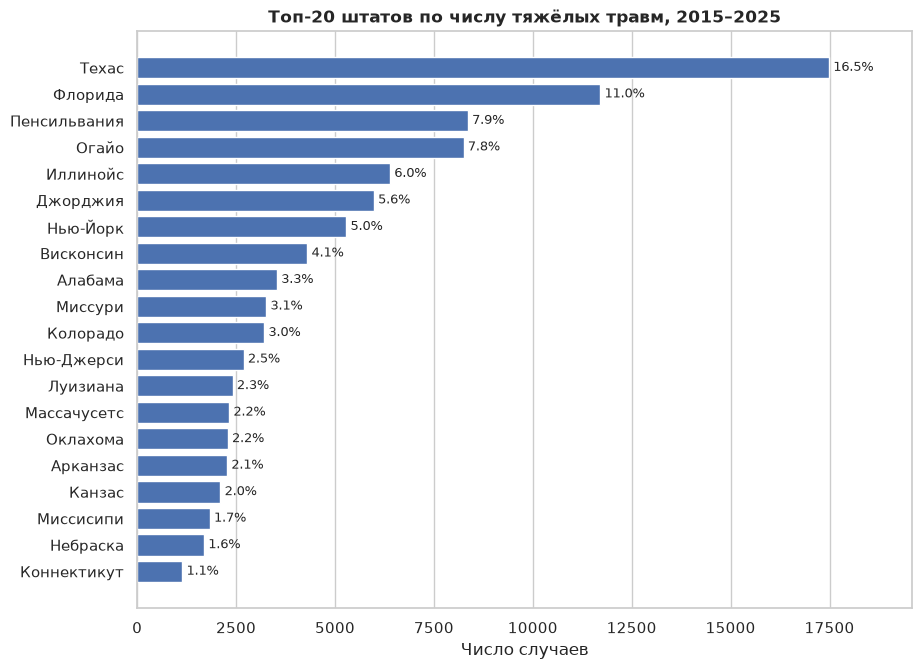

In [4]:
t = st.head(20)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7.5))
    barh_ranked(ax, t["state_ru"] if lang == "ru" else t.index.map(state_en), t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct_of_all"]])
    ax.set_title(tr("Топ-20 штатов по числу тяжёлых травм, 2015–2025",
                    "Top 20 states by number of severe injuries, 2015–2025", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    finish(fig, "07_1_top_states", lang)

### Тяжесть по штатам

Штаты с числом случаев ≥ 500. По горизонтали — число случаев, по вертикали — доля ампутаций; линия — среднее по всем данным. Доля ампутаций в штате во многом отражает его отраслевой состав (см. 7.3): там, где больше обрабатывающей промышленности, больше ампутаций.

Штат × ампутация (штаты ≥ 500 случаев): χ² = 1 524, df = 27, p = 7.98e-305, V Крамера = 0.122
Связь доли обрабатывающей промышленности и доли ампутаций по штатам: ρ Спирмена = 0.80, p = 4.13e-07


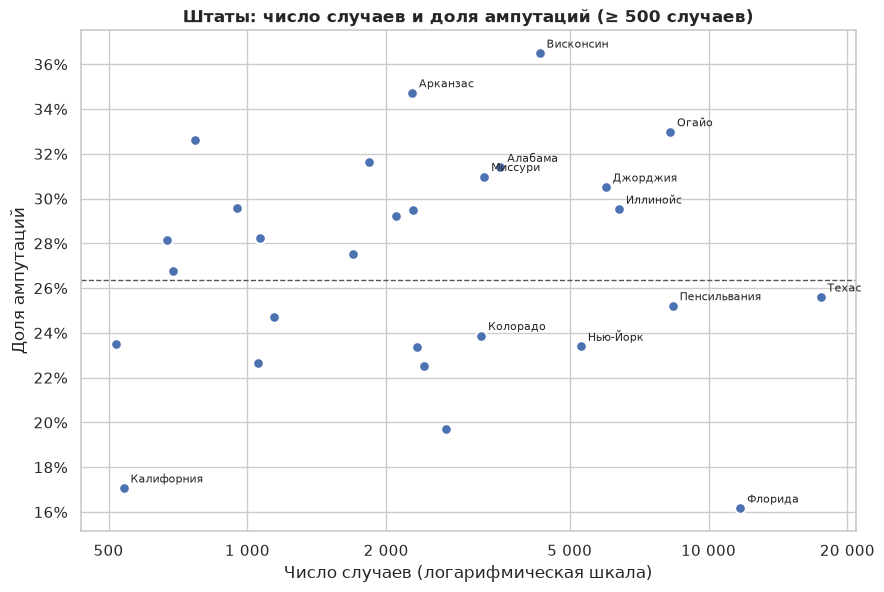

In [5]:
big = st[st["cases"] >= 500]
sub_cases = cases[cases["state"].isin(big.index)]
chi2, p, dof, v, _ = cramers_v(pd.crosstab(sub_cases["state"], sub_cases["amputation"]))
print(f"Штат × ампутация (штаты ≥ 500 случаев): χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")

manuf = pd.crosstab(sub_cases["state"], sub_cases["sector"] == "31-33", normalize="index")[True] * 100
r, p_r = stats.spearmanr(manuf.reindex(big.index), big["pct_amputation"])
print(f"Связь доли обрабатывающей промышленности и доли ампутаций по штатам: ρ Спирмена = {r:.2f}, p = {p_r:.2e}")

for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.scatter(big["cases"], big["pct_amputation"], s=60, color=MAIN, edgecolor="white", lw=1.5, zorder=3)
    ax.axhline(100 * cases["amputation"].mean(), color="#555555", ls="--", lw=1)
    for s, row in big.iterrows():
        if row["cases"] > 3000 or abs(row["pct_amputation"] - 100 * cases["amputation"].mean()) > 7:
            ax.annotate(state_ru(s) if lang == "ru" else state_en(s), (row["cases"], row["pct_amputation"]),
                        xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.set_xscale("log")
    ax.set_xticks([500, 1000, 2000, 5000, 10000, 20000], ["500", "1 000", "2 000", "5 000", "10 000", "20 000"])
    ax.minorticks_off()
    ax.yaxis.set_major_locator(plt.MultipleLocator(2))
    ax.set_title(tr("Штаты: число случаев и доля ампутаций (≥ 500 случаев)",
                    "States: number of cases and share of amputations (≥ 500 cases)", lang))
    ax.set_xlabel(tr("Число случаев (логарифмическая шкала)", "Number of cases (log scale)", lang))
    ax.set_ylabel(tr("Доля ампутаций", "Share of amputations", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    finish(fig, "07_1_states_severity", lang)

## 7.2. Топ-20 городов

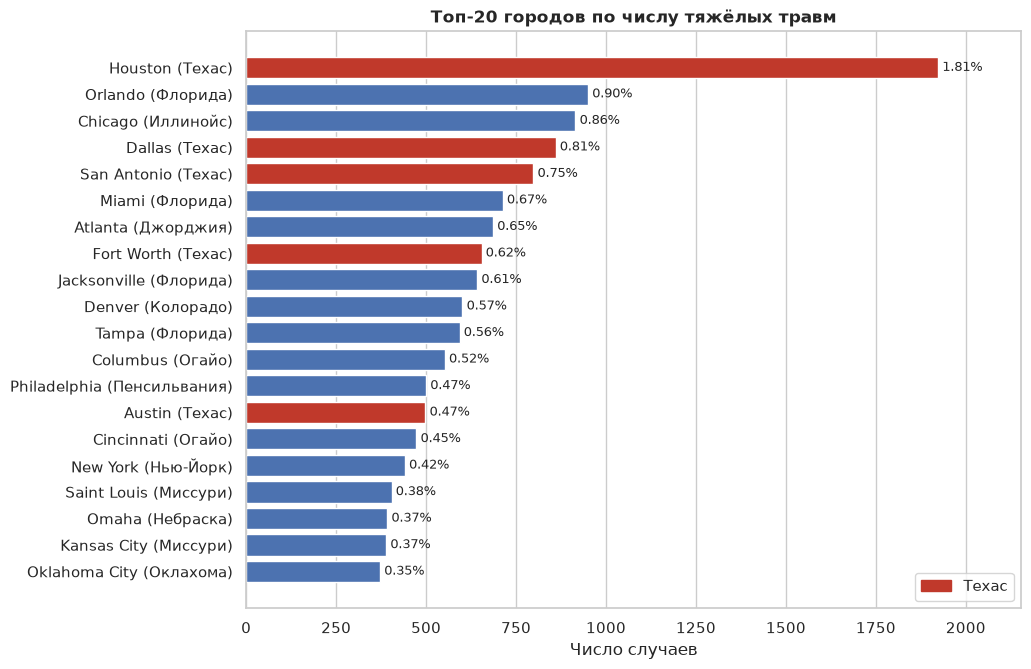

,city,state,cases,pct_of_all
1,HOUSTON,TEXAS,1923,1.81
2,ORLANDO,FLORIDA,950,0.90
3,CHICAGO,ILLINOIS,915,0.86
4,DALLAS,TEXAS,860,0.81
5,SAN ANTONIO,TEXAS,798,0.75
6,MIAMI,FLORIDA,713,0.67
7,ATLANTA,GEORGIA,686,0.65
8,FORT WORTH,TEXAS,654,0.62
9,JACKSONVILLE,FLORIDA,642,0.61
10,DENVER,COLORADO,601,0.57


In [6]:
ct_city = (cases[cases["city"] != "unknown"].groupby(["city", "state"]).size()
           .rename("cases").sort_values(ascending=False).reset_index())
ct_city["pct_of_all"] = 100 * ct_city["cases"] / N
ct_city.index += 1
ct_city.head(20).round(2).to_csv(TABLES_DIR / "07_2_top_cities.csv", encoding="utf-8-sig")

t = ct_city.head(20)
for lang in LANGS:
    labels = [f"{c.title()} ({state_ru(s) if lang == 'ru' else state_en(s)})" for c, s in zip(t["city"], t["state"])]
    fig, ax = plt.subplots(figsize=(10, 7.5))
    barh_ranked(ax, labels, t["cases"], notes=[f"{p:.2f}%" for p in t["pct_of_all"]],
                color=np.where(t["state"] == "TEXAS", ACCENT, MAIN))
    ax.set_title(tr("Топ-20 городов по числу тяжёлых травм", "Top 20 cities by severe injuries", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Техас", "Texas", lang)], loc="lower right")
    finish(fig, "07_2_top_cities", lang)
t.round(2)

## 7.3. Отраслевой состав штатов

SQL 7.3 — ведущий сектор каждого штата. Здесь — состав случаев для 15 крупнейших штатов: четыре крупнейших сектора и «прочие».

In [7]:
lead = (cases.groupby(["state", "sector"]).size().rename("sector_cases").reset_index()
        .sort_values("sector_cases", ascending=False).drop_duplicates("state").set_index("state"))
lead["state_cases"] = st["cases"]
lead["pct_of_state"] = 100 * lead["sector_cases"] / lead["state_cases"]
lead["top_sector_ru"] = lead["sector"].map(lambda s: SECTORS[s][0])
lead = lead.sort_values("state_cases", ascending=False)
lead.round(2).to_csv(TABLES_DIR / "07_3_leading_sector_by_state.csv", encoding="utf-8-sig")
print(lead["top_sector_ru"].value_counts().to_string(), "\n")

main_sec = ["31-33", "23", "48-49", "44-45"]
top15 = st.index[:15]
mix = pd.crosstab(cases["state"], cases["sector"].where(cases["sector"].isin(main_sec), "other"),
                  normalize="index").loc[top15, main_sec + ["other"]] * 100
mix.round(1).to_csv(TABLES_DIR / "07_3_sector_mix_top15_states.csv", encoding="utf-8-sig")
mix.round(1)

top_sector_ru
Обрабатывающая промышленность              29
Транспорт и складирование                  15
Строительство                               5
Государственное управление                  5
Добыча полезных ископаемых, нефти, газа     1
Гостиницы и общепит                         1 



sector,31-33,23,48-49,44-45,other
state,,,,,
TEXAS,26.4,21.4,8.7,7.9,35.7
FLORIDA,14.8,28.5,7.4,10.3,39.1
PENNSYLVANIA,37.4,14.4,10.0,7.0,31.0
OHIO,44.2,12.6,8.9,7.3,27.0
ILLINOIS,40.9,11.5,10.4,7.1,30.0
GEORGIA,39.9,14.9,10.4,7.1,27.6
NEW YORK,23.5,21.7,8.8,9.5,36.5
WISCONSIN,54.0,12.7,4.8,6.0,22.5
ALABAMA,51.7,14.1,6.0,5.4,22.8


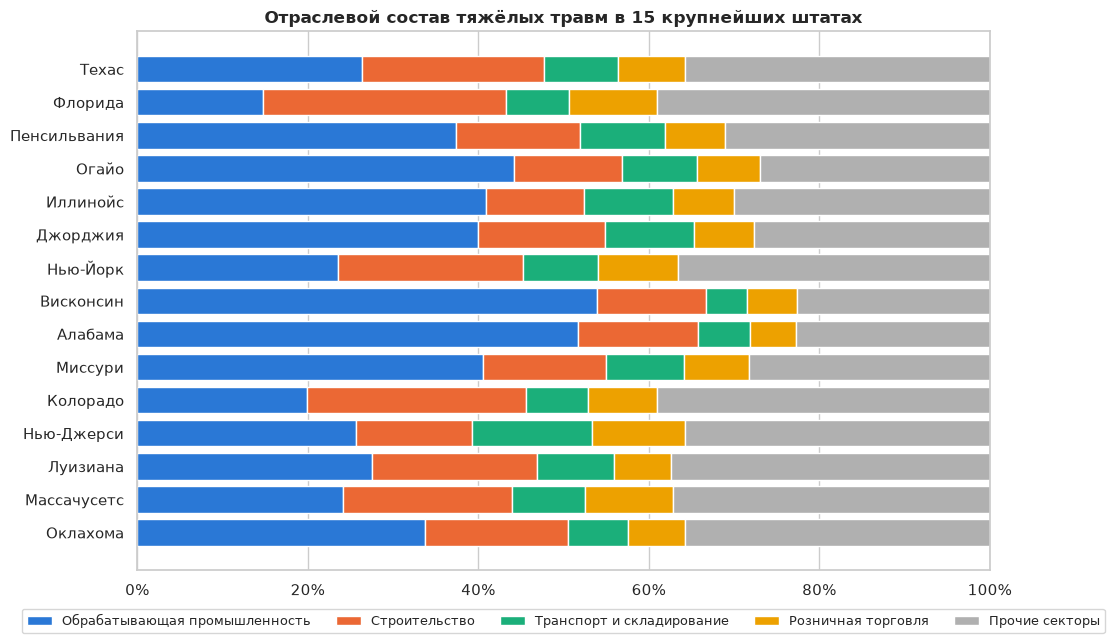

In [8]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 7))
    y = np.arange(len(mix))[::-1]
    left = np.zeros(len(mix))
    for s, color in zip(main_sec + ["other"], SERIES[:4] + ["#b0b0b0"]):
        name = SECTORS[s][k] if s != "other" else tr("Прочие секторы", "Other sectors", lang)
        ax.barh(y, mix[s], left=left, color=color, edgecolor="white", lw=1, label=name)
        left += mix[s].to_numpy()
    ax.set_yticks(y, [state_ru(s) if lang == "ru" else state_en(s) for s in mix.index])
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(tr("Отраслевой состав тяжёлых травм в 15 крупнейших штатах",
                    "Sector mix of severe injuries in the 15 largest states", lang))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncols=5, fontsize=9)
    finish(fig, "07_3_sector_mix", lang)

## 7.4. Изменение по штатам: 2015–2019 против 2021–2025

Как в SQL 7.4: среднее в месяц (60 и 59 месяцев), штаты с ≥ 500 случаев. Добавлен 95% ДИ для отношения частот (rate ratio, приближение Пуассона): если интервал не пересекает 0% — изменение статистически значимо.

In [9]:
d = cases["event_date"]
per = pd.DataFrame({
    "cases_2015_2019": cases[d.between("2015-01-01", "2019-12-31")].groupby("state").size(),
    "cases_2021_2025": cases[d.between("2021-01-01", "2025-11-30")].groupby("state").size(),
}).reindex(big.index).fillna(0)
per["per_month_2015_2019"] = per["cases_2015_2019"] / 60
per["per_month_2021_2025"] = per["cases_2021_2025"] / 59
rr = per["per_month_2021_2025"] / per["per_month_2015_2019"]
se = np.sqrt(1 / per["cases_2015_2019"] + 1 / per["cases_2021_2025"])
per["pct_change"] = 100 * (rr - 1)
per["ci_low"] = 100 * (rr * np.exp(-1.96 * se) - 1)
per["ci_high"] = 100 * (rr * np.exp(1.96 * se) - 1)
per["significant"] = (per["ci_high"] < 0) | (per["ci_low"] > 0)
per = per.sort_values("pct_change")
per.insert(0, "state_ru", per.index.map(state_ru))
per.round(2).to_csv(TABLES_DIR / "07_4_change_by_state.csv", encoding="utf-8-sig")

a, b = per["cases_2015_2019"].sum(), per["cases_2021_2025"].sum()
tot = 100 * ((b / 59) / (a / 60) - 1)
print(f"Все эти штаты вместе: {tot:+.1f}%; значимое снижение: {(per['significant'] & (per['pct_change'] < 0)).sum()} "
      f"из {len(per)}, значимый рост: {(per['significant'] & (per['pct_change'] > 0)).sum()}")
per.round(1)

Все эти штаты вместе: -13.7%; значимое снижение: 21 из 28, значимый рост: 0


,state_ru,cases_2015_2019,cases_2021_2025,per_month_2015_2019,per_month_2021_2025,pct_change,ci_low,ci_high,significant
state,,,,,,,,,
MISSISSIPPI,Миссисипи,1049,626,17.5,10.6,-39.3,-45.0,-33.0,True
NORTH DAKOTA,Северная Дакота,533,365,8.9,6.2,-30.4,-39.0,-20.4,True
LOUISIANA,Луизиана,1291,930,21.5,15.8,-26.7,-32.7,-20.3,True
COLORADO,Колорадо,1683,1232,28.0,20.9,-25.6,-30.8,-19.9,True
MASSACHUSETTS,Массачусетс,1207,922,20.1,15.6,-22.3,-28.7,-15.4,True
MONTANA,Монтана,266,205,4.4,3.5,-21.6,-34.7,-6.0,True
SOUTH DAKOTA,Южная Дакота,354,275,5.9,4.7,-21.0,-32.5,-7.5,True
KANSAS,Канзас,1061,851,17.7,14.4,-18.4,-25.5,-10.7,True
WISCONSIN,Висконсин,2182,1758,36.4,29.8,-18.1,-23.1,-12.8,True


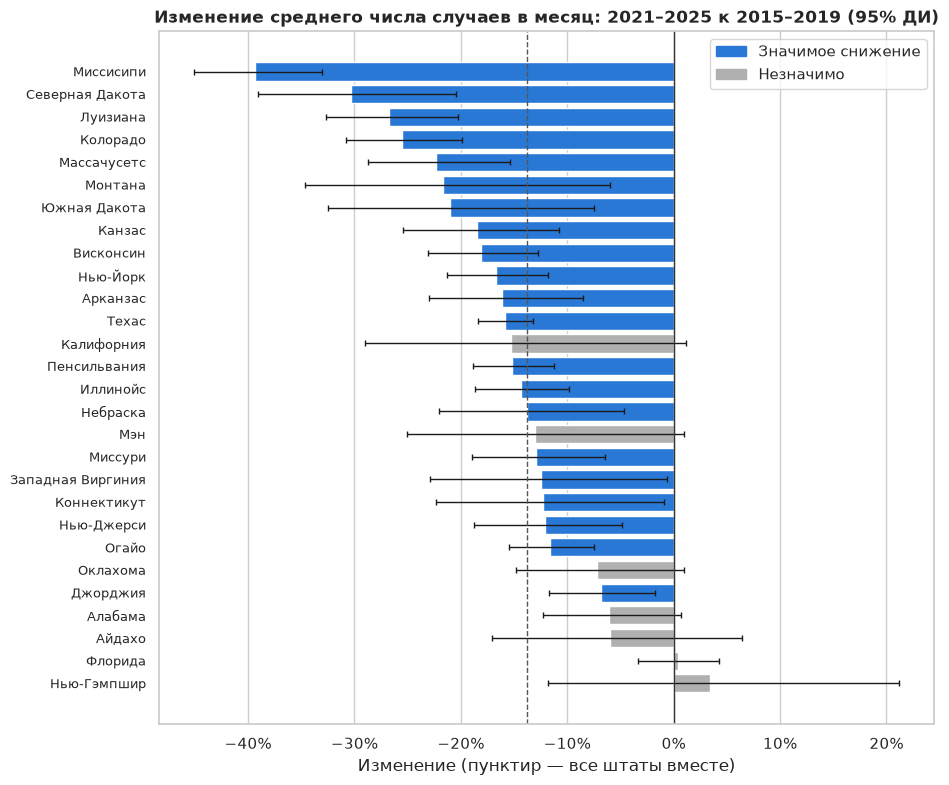

In [10]:
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 9))
    y = np.arange(len(per))[::-1]
    colors = np.where(~per["significant"], "#b0b0b0", np.where(per["pct_change"] < 0, SERIES[0], ACCENT))
    ax.barh(y, per["pct_change"], color=colors,
            xerr=[per["pct_change"] - per["ci_low"], per["ci_high"] - per["pct_change"]],
            capsize=2, error_kw={"lw": 1})
    ax.axvline(0, color="#333333", lw=1)
    ax.axvline(tot, color="#555555", ls="--", lw=1)
    ax.set_yticks(y, [state_ru(s) if lang == "ru" else state_en(s) for s in per.index], fontsize=9)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(tr("Изменение среднего числа случаев в месяц: 2021–2025 к 2015–2019 (95% ДИ)",
                    "Change in cases per month: 2021–2025 vs 2015–2019 (95% CI)", lang))
    ax.set_xlabel(tr("Изменение (пунктир — все штаты вместе)", "Change (dashed — all states combined)", lang))
    kinds = [(SERIES[0], ("Значимое снижение", "Significant decrease")),
             (ACCENT, ("Значимый рост", "Significant increase")),
             ("#b0b0b0", ("Незначимо", "Not significant"))]
    kinds = [(c, t) for c, t in kinds if (colors == c).any()]
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c, _ in kinds],
              labels=[tr(*t, lang) for _, t in kinds], loc="upper right")
    finish(fig, "07_4_change_by_state", lang)

## Выводы

1. **Травмы сильно сконцентрированы географически:** Техас (16,5%) и Флорида (11,0%) дают 27,5% случаев, десять штатов — 70%. Среди городов лидирует Хьюстон (1,8%), в топ-20 пять городов Техаса и четыре — Флориды. Это абсолютные числа без учёта численности работников.
2. **Данные покрывают прежде всего штаты под федеральной OSHA** (97,6% случаев). 22 штата и территории с собственной программой State Plan (в том числе California, Washington, Michigan) дают лишь 2,4% — их низкие значения не означают безопасность.
3. **Доля ампутаций по штатам различается от 17% (Флорида) до 36% (Висконсин)** (χ² = 1 524, V Крамера = 0,12) и почти полностью объясняется отраслевым составом: корреляция доли обрабатывающей промышленности и доли ампутаций по штатам ρ = 0,80 (p < 0,001). В Висконсине и Алабаме на промышленность приходится более половины случаев, во Флориде ведущий сектор — строительство (28,5%).
4. **Ведущий сектор** в 29 штатах — обрабатывающая промышленность, в 15 — транспорт и складирование, в 5 — строительство.
5. **Снижение 2021–2025 к 2015–2019 почти повсеместно:** −13,7% в среднем в месяц по штатам с ≥ 500 случаев; значимое снижение в 21 из 28 штатов (95% ДИ не пересекает 0), значимого роста нет ни в одном. Сильнее всего снизилось в Миссисипи (−39%), Северной Дакоте (−30%), Луизиане (−27%) и Колорадо (−26%); во Флориде и Нью-Гэмпшире уровень не изменился.